In [ ]:
#import necessary libries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
#Load the dataset
df=pd.read_csv("Churn_Modelling.csv")

In [ ]:
#understand the data
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.dtypes

,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64


In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
#check null values
df.isna().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
#check duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df["Exited"].value_counts())
print(df["Exited"].value_counts(normalize=True) * 100)

Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


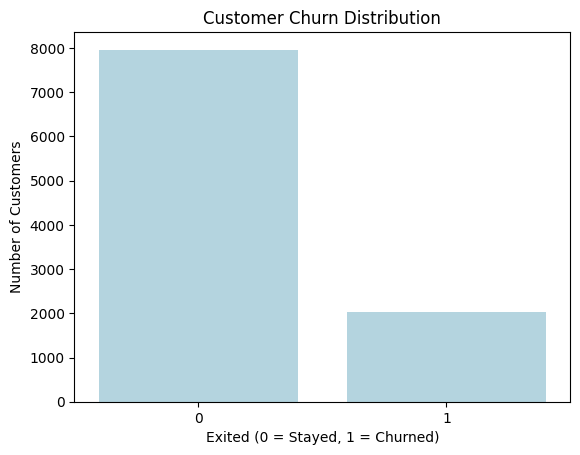

In [ ]:
# data visualizations
sns.countplot(data=df, x="Exited",color="lightblue")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()


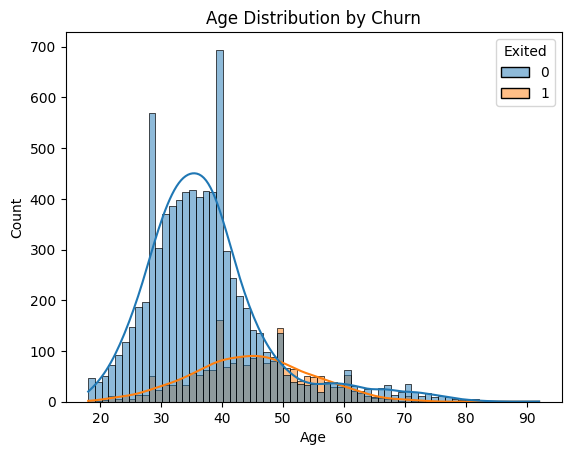

In [ ]:
#Analyze customer age
sns.histplot(data=df, x="Age", hue="Exited", kde=True)
plt.title("Age Distribution by Churn")
plt.show()

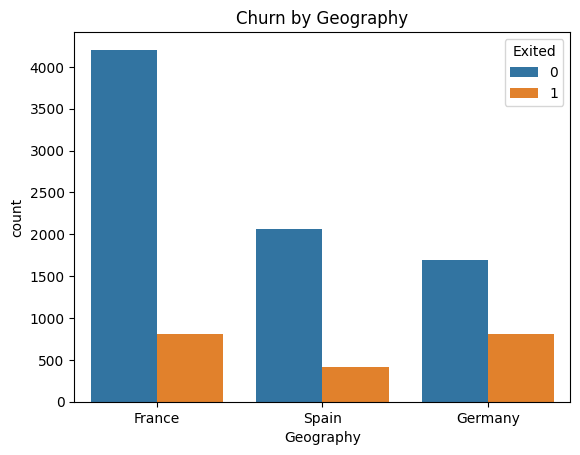

In [ ]:
#Analyze churn by geography
sns.countplot(data=df, x="Geography", hue="Exited")
plt.title("Churn by Geography")
plt.show()

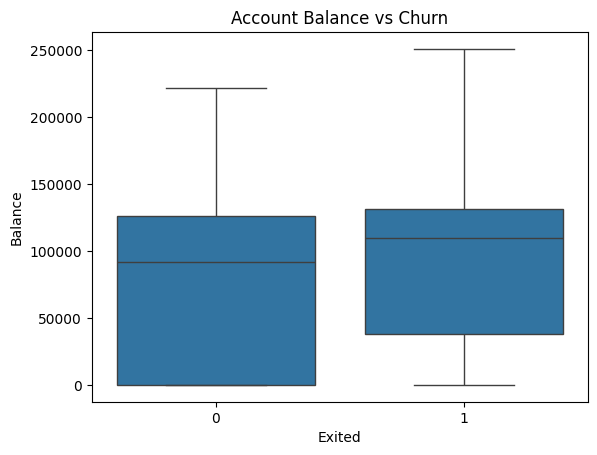

In [ ]:
#Analyze account balance
sns.boxplot(data=df, x="Exited", y="Balance")
plt.title("Account Balance vs Churn")
plt.show()

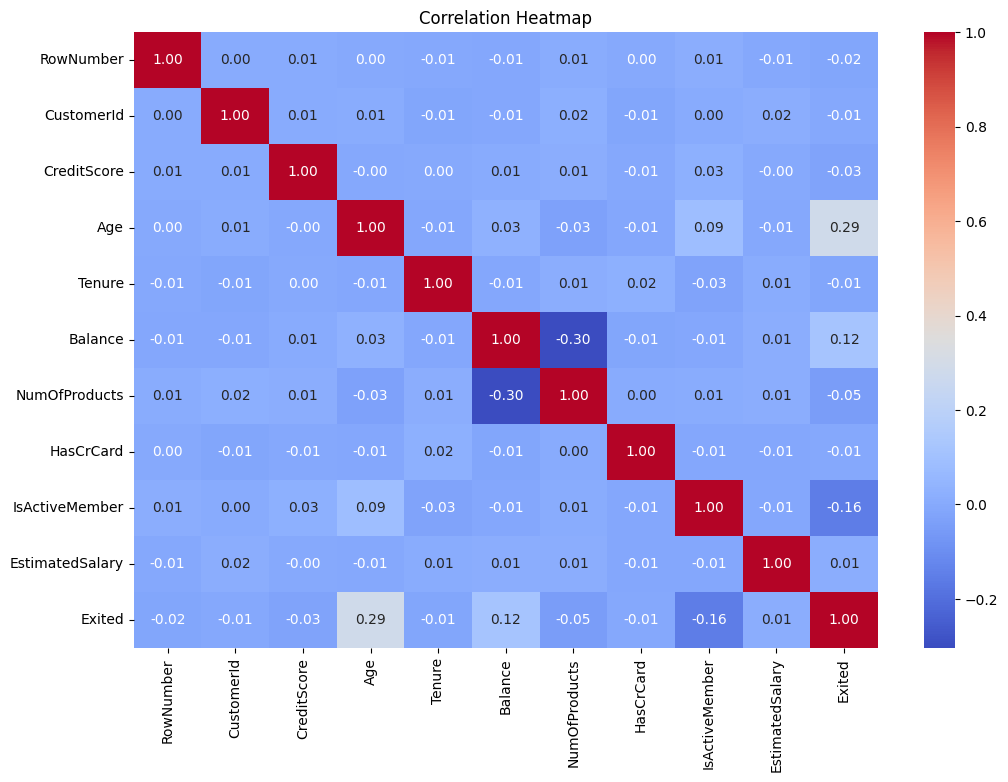

In [ ]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Data Preprocessing


In [ ]:
#Check the dataset
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())

(10000, 14)
RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
0


In [ ]:
#Remove irrelevant columns
df = df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    errors="ignore"
)

print(df.head())

   CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
0          619    France  Female   42       2       0.00              1   
1          608     Spain  Female   41       1   83807.86              1   
2          502    France  Female   42       8  159660.80              3   
3          699    France  Female   39       1       0.00              2   
4          850     Spain  Female   43       2  125510.82              1   

   HasCrCard  IsActiveMember  EstimatedSalary  Exited  
0          1               1        101348.88       1  
1          0               1        112542.58       0  
2          1               0        113931.57       1  
3          0               0         93826.63       0  
4          1               1         79084.10       0  


In [ ]:
#Separate features and target
X = df.drop(columns=["Exited"])
y = df["Exited"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 10)
Target shape: (10000,)


In [ ]:
#Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(include=["object", "category"]).columns

print("Numerical columns:", numeric_cols.tolist())
print("Categorical columns:", categorical_cols.tolist())

Numerical columns: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical columns: ['Geography', 'Gender']


In [ ]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 10)
Testing data: (2000, 10)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 13)
Processed testing shape: (2000, 13)


In [ ]:
# Feature Engineering & Feature Selection

In [ ]:
# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "55+"]
)

# Identify customers with zero balance
df["ZeroBalance"] = (df["Balance"] == 0).astype(int)

print(df[["Age", "AgeGroup", "Balance", "ZeroBalance"]].head())

   Age AgeGroup    Balance  ZeroBalance
0   42    36-45       0.00            1
1   41    36-45   83807.86            0
2   42    36-45  159660.80            0
3   39    36-45       0.00            1
4   43    36-45  125510.82            0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train_processed, y_train)

feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(15))

num__Age                  0.252461
num__EstimatedSalary      0.140067
num__Balance              0.139128
num__CreditScore          0.135254
num__NumOfProducts        0.126604
num__Tenure               0.082190
num__IsActiveMember       0.036510
cat__Geography_Germany    0.025982
num__HasCrCard            0.018262
cat__Geography_France     0.012505
cat__Gender_Female        0.010754
cat__Gender_Male          0.010251
cat__Geography_Spain      0.010033
dtype: float64


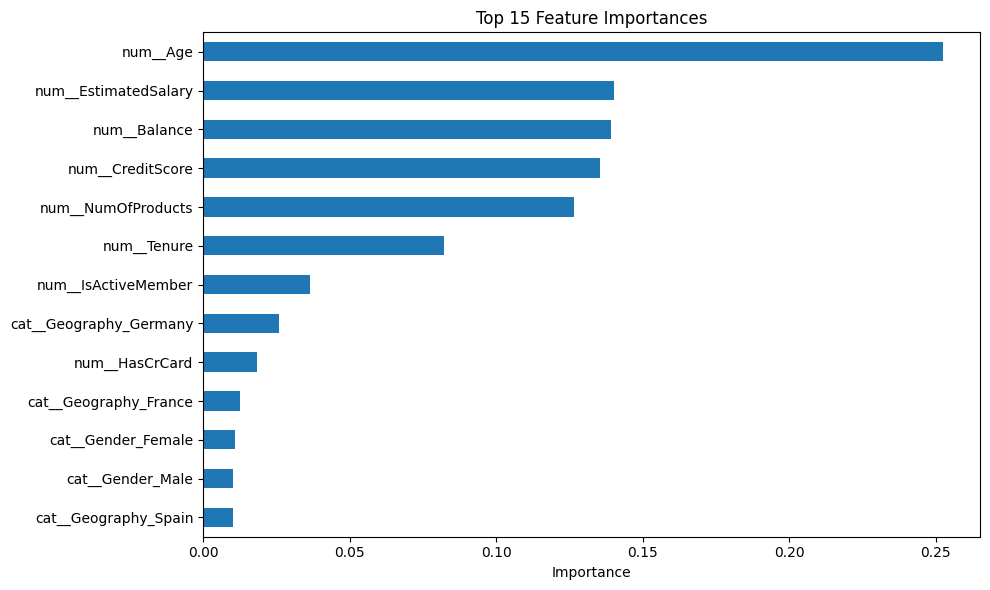

In [ ]:
importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 15 Feature Importances"
)

plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
# Model Training


In [ ]:
#Train Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

lr_pred = lr_model.predict(X_test_processed)

In [ ]:
#tarin decion tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)

In [ ]:
#train random forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": (lr_model, lr_pred),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (model, pred) in models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
2        Random Forest     0.852      0.660   0.563     0.607    0.855
1        Decision Tree     0.758      0.445   0.767     0.563    0.831
0  Logistic Regression     0.714      0.387   0.700     0.499    0.777


In [ ]:
#Generate a classification report
from sklearn.metrics import classification_report

print("Random Forest")
print(classification_report(y_test, rf_pred))

Random Forest
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      1593
           1       0.66      0.56      0.61       407

    accuracy                           0.85      2000
   macro avg       0.78      0.74      0.76      2000
weighted avg       0.85      0.85      0.85      2000



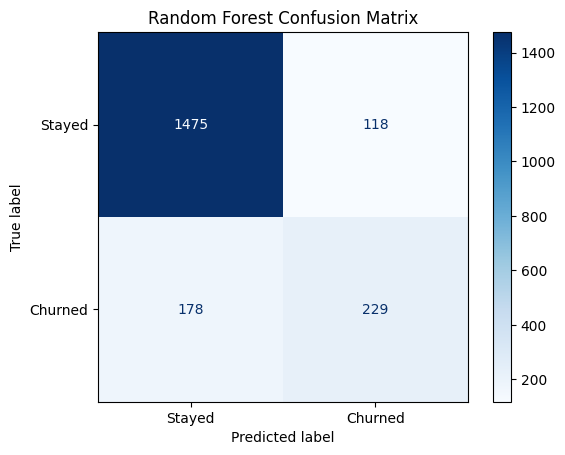

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
#Hyperparameter Tuning
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 8, 10, 12, 15, 20],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 6],
    "max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best Cross-Validation F1:")
print(round(random_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'max_depth': 20}
Best Cross-Validation F1:
0.6265


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

best_model = random_search.best_estimator_

tuned_pred = best_model.predict(X_test_processed)
tuned_prob = best_model.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Precision:", round(precision_score(y_test, tuned_pred), 4))
print("Recall:", round(recall_score(y_test, tuned_pred), 4))
print("F1-score:", round(f1_score(y_test, tuned_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_pred))

Accuracy: 0.842
Precision: 0.6041
Recall: 0.6486
F1-score: 0.6256
ROC-AUC: 0.8601

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.60      0.65      0.63       407

    accuracy                           0.84      2000
   macro avg       0.76      0.77      0.76      2000
weighted avg       0.85      0.84      0.84      2000



In [ ]:
import joblib
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

# Train the complete pipeline on raw training data
final_pipeline.fit(X_train, y_train)

# Save the complete pipeline
joblib.dump(final_pipeline, "bank_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
sample_customer = X_test.iloc[[0]]

prediction = final_pipeline.predict(sample_customer)[0]
probability = final_pipeline.predict_proba(sample_customer)[0][1]

if prediction == 1:
    print("Prediction: Customer may churn")
else:
    print("Prediction: Customer likely to stay")

print(f"Churn probability: {probability:.2%}")

Prediction: Customer likely to stay
Churn probability: 7.83%


In [ ]:
loaded_model = joblib.load("bank_churn_model.pkl")

prediction = loaded_model.predict(sample_customer)

print("Loaded model prediction:", prediction[0])

Loaded model prediction: 0
